## Load the 2024 - 2026 property sales data

In [1]:
import pandas as pd
import fpsnippets


property_sales_24= pd.read_csv("data/2024_Property_Sales.csv")
property_sales_25= pd.read_csv("data/2025_Property_Sales.csv")
property_sales_26= pd.read_csv("data/2026_Property_Sales.csv")

property_sales = pd.concat([property_sales_24, property_sales_25, property_sales_26], ignore_index=True)
print(property_sales.shape)
print(property_sales.index.nunique())
property_sales.head(10)


(86987, 26)
86987


,_id,PARID,FULL_ADDRESS,PROPERTYHOUSENUM,PROPERTYFRACTION,PROPERTYADDRESSDIR,PROPERTYADDRESSSTREET,PROPERTYADDRESSSUF,PROPERTYADDRESSUNITDESC,PROPERTYUNITNO,...,MUNIDESC,RECORDDATE,SALEDATE,PRICE,DEEDBOOK,DEEDPAGE,SALECODE,SALEDESC,INSTRTYP,INSTRTYPDESC
0,18818218,0220B00015000000,"1308 ANDERSON RD, PITTSBURGH, PA 15209",1308.0,,NaN,ANDERSON,RD,NaN,NaN,...,Shaler,2024-05-06,2024-05-02,147000.0,19659,106.0,37,ESTATE SALE,DE,DEED
1,18818219,0036M00075000000,"1820 YOUNGER AVE, PITTSBURGH, PA 15216",1820.0,,NaN,YOUNGER,AVE,NaN,NaN,...,20th Ward - PITTSBURGH,2024-05-10,2024-04-19,80000.0,19665,377.0,14,TIME ON MARKET (INSUFF/EXCESS),GW,GENERAL WARRANTY
2,18818220,0381P00067000000,"2813 RIVERVIEW ST, MC KEESPORT, PA 15132",2813.0,,NaN,RIVERVIEW,ST,NaN,NaN,...,7th Ward - McKEESPORT,2024-06-06,2024-05-24,1.0,19694,217.0,3,LOVE AND AFFECTION SALE,SW,SPECIAL WARRANTY
3,18818221,0054E00005000000,"100 BOUNDARY ST, PITTSBURGH, PA 15207",100.0,,NaN,BOUNDARY,ST,NaN,NaN,...,14th Ward - PITTSBURGH,2024-11-04,2024-09-24,1.0,19852,25.0,H,MULTI-PARCEL SALE,DE,DEED
4,18818222,0826K00009000000,"583 CUMBERLAND RD, PITTSBURGH, PA 15237",583.0,,NaN,CUMBERLAND,RD,NaN,NaN,...,McCandless,2024-06-18,2024-06-12,1.0,19707,237.0,H,MULTI-PARCEL SALE,QC,QUIT CLAIM
5,18818223,0011J00165000A00,"51 VAN BRAAM ST, PITTSBURGH, PA 15219",51.0,,NaN,VAN BRAAM,ST,NaN,NaN,...,1st Ward - PITTSBURGH,2024-04-02,2024-02-29,46000.0,19624,355.0,GV,GOVERNMENT SALE,TS,TREASURER DEED
6,18818224,0826K00054000000,"525 CUMBERLAND RD, PITTSBURGH, PA 15237",525.0,,NaN,CUMBERLAND,RD,NaN,NaN,...,McCandless,2024-06-18,2024-06-12,1.0,19707,242.0,3,LOVE AND AFFECTION SALE,QC,QUIT CLAIM
7,18818225,0482S00022000000,"740 WHEATLAND CIR, BRIDGEVILLE, PA 15017",740.0,,NaN,WHEATLAND,CIR,NaN,NaN,...,South Fayette,2024-06-10,2024-05-29,134900.0,19697,139.0,0,VALID SALE,CO,CORRECTIVE DEED
8,18818226,0970G00216000000,"0 OLD LEECHBURG RD, PITTSBURGH, PA 15239",0.0,,NaN,OLD LEECHBURG,RD,NaN,NaN,...,Plum,2024-02-16,2024-02-14,1.0,19578,8.0,99,CORRECTIVE DEED / DUPLICATE SALE,CO,CORRECTIVE DEED
9,18818227,0814D00275000000,"14 BEAVER ST, AMBRIDGE, PA 15003",14.0,,NaN,BEAVER,ST,NaN,NaN,...,Leetsdale,2024-12-16,2024-11-27,NaN,19894,439.0,32,COURT ORDERED SALE,CR,COURT ORDER


## what types of sales are there? 
The 'SALEDESC' column describes the type of each sale. Not every recorded sale reflects a real market price. For example, "LOVE AND AFFECTION SALE" is a cheap sale between family members, and "SHERIFF SALE" is a type of foreclosure sale.

In [2]:
print(property_sales["SALEDESC"].value_counts())

SALEDESC
VALID SALE                                 26486
LOVE AND AFFECTION SALE                    20387
MULTI-PARCEL SALE                          12947
TIME ON MARKET (INSUFF/EXCESS)              9594
OTHER INVALID SALES INDICATED               3486
CORPORATION TRANSFER                        3180
CORRECTIVE DEED / DUPLICATE SALE            2981
SHERIFF SALE                                1717
BUILDING NOT YET ASSESSED                   1386
SALE NOT ANALYZED                           1115
GOVERNMENT SALE                             1037
NO ASSESSED VALUATION                        510
QUIT CLAIM                                   419
DATE OF TRANSFER (RECORD YR <> SALE YR)      321
NOT APPLICABLE                               302
ESTATE SALE                                  281
EXEMPT BUYER OR SELLER                       264
PREFERENTIAL ASMT                            181
BANK/FINANCIAL INSTITUTION                   131
CITY TREASURER SALE                           97
SALE OF PRE

## Which municipalities (city limits) are in the data?

A municipality is just the formal word for a city, town or village. This dataset covers all of Allegheny County, which has 130 municipalities, including the city of Pittsburgh and suburbs like Mt. Lebanon, Ross, and Castle Shannon.

The 'MUNIDESC' column tells us each property's municipality. Pittsburgh properties are labeled by ward, like "14th Ward - PITTSBURGH"

Since our project is only about Pittsburgh neighborhoods, I use this column to keep only the sales inside the city. This avoids mixing in housing prices from homes that have a Pittsburgh address but are actually located outside the city limits.


In [3]:
print(property_sales["MUNIDESC"].value_counts().head(30))

MUNIDESC
Penn Hills                3147
Ross                      2158
19th Ward - PITTSBURGH    2150
Moon                      1896
Bethel Park               1824
Mt.Lebanon                1822
Shaler                    1801
14th Ward - PITTSBURGH    1707
Plum                      1700
Monroeville               1682
McCandless                1598
South Fayette             1502
North Fayette             1318
West Mifflin              1278
Robinson                  1217
West Deer                 1212
10th Ward - PITTSBURGH    1181
Hampton                   1168
Baldwin Boro              1154
Scott                     1149
Upper St. Clair           1138
20th Ward - PITTSBURGH    1126
Wilkinsburg               1098
Marshall                  1034
Jefferson Hills            992
South Park                 952
Franklin Park              951
Collier                    940
Pine                       920
15th Ward - PITTSBURGH     911
Name: count, dtype: int64


## Filter to Pittsbrugh 

I keep only sales whose offical city or town is a Pittsburgh ward, so every property is inside the city limits. 

In [4]:
# Keep only real market sales
valid_property_sales = property_sales[property_sales["SALEDESC"].str.strip()=="VALID SALE"]
print("valid property sales:", valid_property_sales.shape)

Not_Pittsburgh_property_sales = valid_property_sales[valid_property_sales["PROPERTYCITY"].str.strip() !="PITTSBURGH"]
# Keep only sales insde Pittsburgh city limits
Pittsburgh_property_sales = valid_property_sales[valid_property_sales["MUNIDESC"].str.contains("PITTSBURGH")]
print("non-Pittsburgh property sales:", Not_Pittsburgh_property_sales.shape)
print("Pittsburgh property sales:", Pittsburgh_property_sales.shape)
print(Pittsburgh_property_sales["MUNIDESC"].unique())



valid property sales: (26486, 26)
non-Pittsburgh property sales: (11928, 26)
Pittsburgh property sales: (5099, 26)
['4th Ward - PITTSBURGH' '12th Ward - PITTSBURGH' '19th Ward - PITTSBURGH'
 '28th Ward - PITTSBURGH' '10th Ward - PITTSBURGH'
 '24th Ward - PITTSBURGH' '31st Ward - PITTSBURGH'
 '27th Ward - PITTSBURGH' '15th Ward - PITTSBURGH'
 '11th Ward - PITTSBURGH' '20th Ward - PITTSBURGH'
 '29th Ward - PITTSBURGH' '16th Ward - PITTSBURGH'
 '14th Ward - PITTSBURGH' '2nd Ward - PITTSBURGH' '17th Ward - PITTSBURGH'
 '6th Ward - PITTSBURGH' '25th Ward - PITTSBURGH' '26th Ward - PITTSBURGH'
 '8th Ward - PITTSBURGH' '9th Ward - PITTSBURGH' '7th Ward - PITTSBURGH'
 '32nd Ward - PITTSBURGH' '23rd Ward - PITTSBURGH' '3rd Ward - PITTSBURGH'
 '21st Ward - PITTSBURGH' '18th Ward - PITTSBURGH'
 '22nd Ward - PITTSBURGH' '13th Ward - PITTSBURGH'
 '30th Ward - PITTSBURGH' '1st Ward  - PITTSBURGH' '5th Ward - PITTSBURGH']


In [5]:
Not_Pittsburgh_property_sales[["FULL_ADDRESS", "MUNIDESC", "PROPERTYZIP", "PRICE"]].head(10)

,FULL_ADDRESS,MUNIDESC,PROPERTYZIP,PRICE
7,"740 WHEATLAND CIR, BRIDGEVILLE, PA 15017",South Fayette,15017,134900.0
14,"2017 HEMLOCK LN, MARS, PA 16046",Marshall,16046,425000.0
17,"15-16 RING ST, RURAL RIDGE, PA 15075",Indiana,15075,198000.0
20,"215 SPARTAN DR, MONROEVILLE, PA 15146",Monroeville,15146,216000.0
23,"2662 QUAIL RIDGE LN, WEXFORD, PA 15090",Franklin Park,15090,255000.0
24,"108 CAMBRIA HILL DR, TARENTUM, PA 15084",East Deer,15084,170000.0
30,"2204 SUPERIOR ST, BETHEL PARK, PA 15102",Bethel Park,15102,325000.0
31,"9208 SUNDANCE DR, BRIDGEVILLE, PA 15017",South Fayette,15017,330000.0
52,"218 ROBERTS ST, WEST MIFFLIN, PA 15122",West Mifflin,15122,150000.0
54,"830 MARKMAN PARK RD, BADEN, PA 15005",Marshall,15005,475000.0


In [6]:
Pittsburgh_property_sales[["FULL_ADDRESS", "MUNIDESC", "PROPERTYZIP", "PRICE"]].head(10)

,FULL_ADDRESS,MUNIDESC,PROPERTYZIP,PRICE
25,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",4th Ward - PITTSBURGH,15213,379000.0
39,"7131 VASSAR ST, PITTSBURGH, PA 15206",12th Ward - PITTSBURGH,15206,26500.0
45,"1509 WAREMAN AVE, PITTSBURGH, PA 15226",19th Ward - PITTSBURGH,15226,302500.0
48,"1212 HOLLYWOOD ST, PITTSBURGH, PA 15205",28th Ward - PITTSBURGH,15205,138000.0
69,"5415 CARNEGIE ST, PITTSBURGH, PA 15201",10th Ward - PITTSBURGH,15201,323500.0
85,"2009 VERONICA ST, PITTSBURGH, PA 15212",24th Ward - PITTSBURGH,15212,179000.0
97,"4411 ARMORHILL AVE, HOMESTEAD, PA 15120",31st Ward - PITTSBURGH,15120,148000.0
112,"1 TRIMONT LN, APT 750C, PITTSBURGH, PA 15211",19th Ward - PITTSBURGH,15211,350000.0
126,"1112 GLADYS AVE, PITTSBURGH, PA 15216",19th Ward - PITTSBURGH,15216,148500.0
130,"6 ELMONT ST, PITTSBURGH, PA 15205",28th Ward - PITTSBURGH,15205,217500.0


## Median home price by ZIP code
I group the Pittsburgh property sales by Zip code and find the median home price for each one. I use the median instead of the average because some neighborhoods have million dollar properties that would drive the average up. 

In [7]:
Home_price_by_zip = Pittsburgh_property_sales.groupby("PROPERTYZIP")["PRICE"].agg(["median", "count"])

Home_price_by_zip = Home_price_by_zip.sort_values("median")

Home_price_by_zip

,median,count
PROPERTYZIP,,
15235,107500.0,2
15106,129000.0,8
15210,144000.0,322
15227,151500.0,76
15204,157000.0,93
15120,182148.5,28
15219,183500.0,87
15214,185000.0,139
15216,189700.0,226


## Match ZIP codes to neighborhoods

use 'fpsnippets' helper to find which neighborhoods are in each zip code.


In [8]:
rows = []

for zip_code in Home_price_by_zip.index:
    neighborhoods = fpsnippets.zip_to_neighborhoods(zip_code)
    if neighborhoods:
        for neighborhood in neighborhoods:
            rows.append({"PROPERTYZIP": zip_code, "neighborhood":neighborhood})

zip_neighborhoods = pd.DataFrame(rows)
print(zip_neighborhoods.shape)
zip_neighborhoods.head(10)

(224, 2)


,PROPERTYZIP,neighborhood
0,15235,Homewood North
1,15235,Lincoln-Lemington-Belmar
2,15235,East Hills
3,15106,East Carnegie
4,15210,Knoxville
5,15210,Arlington Heights
6,15210,Brookline
7,15210,Hays
8,15210,Beltzhoover
9,15210,Allentown


## Connect each sale to its neighborhoods
Some neighborhoods appear in more than one zip code. For example, Hays shows up in both 15227 and 15210, because the neighborhood crosses two zip code areas.

I connect the sales with the zip to neighborhood table, so each sale is linked to the neighborhoods in its zip code. 

In [9]:
sales_by_neighborhood = Pittsburgh_property_sales.merge(zip_neighborhoods, on="PROPERTYZIP")
print(sales_by_neighborhood.shape)
sales_by_neighborhood[["FULL_ADDRESS","PROPERTYZIP","neighborhood","PRICE"]].head(10)

(49863, 27)


,FULL_ADDRESS,PROPERTYZIP,neighborhood,PRICE
0,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Squirrel Hill North,379000.0
1,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Bedford Dwellings,379000.0
2,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,North Oakland,379000.0
3,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Lower Lawrenceville,379000.0
4,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Bluff,379000.0
5,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Greenfield,379000.0
6,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Polish Hill,379000.0
7,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Central Oakland,379000.0
8,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Bloomfield,379000.0
9,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,Hazelwood,379000.0


## Median ome price by neighborhood 

I group the sales by neighborhood and find the median price for each one. 

In [10]:
home_price_by_neighborhood = sales_by_neighborhood.groupby("neighborhood")["PRICE"].agg(["median", "count"])
home_price_by_neighborhood = home_price_by_neighborhood.sort_values("median")
home_price_by_neighborhood.head(10)

,median,count
neighborhood,,
Knoxville,144000.0,322
Mt. Oliver,144000.0,322
St. Clair,145000.0,398
Esplen,157000.0,93
Chartiers City,157000.0,93
Hays,160000.0,611
Elliott,179900.0,227
Sheraden,179900.0,227
Carrick,180100.0,753


## Which neighborhoods fit the family's budget?

Our family has set a budget of $40,000. A neighborhood fits the budget if its median home price is $400,000 or less.

In [11]:
budget = 450000
home_price_by_neighborhood["within_budget"]= home_price_by_neighborhood["median"] <= budget
print(home_price_by_neighborhood["within_budget"].value_counts())
home_price_by_neighborhood.head(25)

within_budget
True    90
Name: count, dtype: int64


,median,count,within_budget
neighborhood,,,
Knoxville,144000.0,322,True
Mt. Oliver,144000.0,322,True
St. Clair,145000.0,398,True
Esplen,157000.0,93,True
Chartiers City,157000.0,93,True
Hays,160000.0,611,True
Elliott,179900.0,227,True
Sheraden,179900.0,227,True
Carrick,180100.0,753,True


## Problem with zip code method 

With the zip code method that I used, all 90 neighborhoods fell under the budget, and some neighborhoods got the exact price. For example, Middle Hill and Crawford-Roberts both show $190,000, because both share same zip code (15219) and one zip code covers many neighborhoods, so they get the exact same price.

To fix this, I match each sale to its exact neigborhood using WPRDC's Parcel Centroids dataset (March 2025), which lists the city neighborhood for every property.

In [12]:
url = "https://data.wprdc.org/dataset/2536e5e2-253b-4c58-969d-687828bb94c6/resource/3fab7152-3f11-4788-8372-4c33f86ea813/download/parcel_centroids_2025_march.csv"

# Load parcel centroids data from URL
parcel_centroids = pd.read_csv(url, low_memory=False)

# Keep only Pittsburgh properties, and only the columns I need

Pittsburgh_parcel_centroids = parcel_centroids[parcel_centroids["MUNI_NAME"]== "PITTSBURGH"]
Pittsburgh_parcel_centroids = Pittsburgh_parcel_centroids[["PIN", "CITY_NEIGHBORHOOD"]]
print(Pittsburgh_parcel_centroids.shape)
Pittsburgh_parcel_centroids.head()





(142812, 2)


,PIN,CITY_NEIGHBORHOOD
286922,0004C00125000001,South Shore
286923,0004C00265000A00,South Shore
286924,0004C00265000000,South Shore
286925,0004C00123000A00,South Shore
286926,0004C00115000100,South Shore


## Match each sale to its exact neighborhood

I merge the sales with the parcel data using the parcel ID, so each sale gets its own neighborhood.

In [13]:
sales_with_neighborhoods = Pittsburgh_property_sales.merge(Pittsburgh_parcel_centroids, left_on="PARID", right_on="PIN")
print(sales_with_neighborhoods.shape)
sales_with_neighborhoods[["FULL_ADDRESS","PROPERTYZIP","CITY_NEIGHBORHOOD","PRICE"]].head(10)

(5097, 28)


,FULL_ADDRESS,PROPERTYZIP,CITY_NEIGHBORHOOD,PRICE
0,"540 N NEVILLE ST, UNIT 502, PITTSBURGH, PA 15213",15213,North Oakland,379000.0
1,"7131 VASSAR ST, PITTSBURGH, PA 15206",15206,Lincoln-Lemington-Belmar,26500.0
2,"1509 WAREMAN AVE, PITTSBURGH, PA 15226",15226,Brookline,302500.0
3,"1212 HOLLYWOOD ST, PITTSBURGH, PA 15205",15205,Crafton Heights,138000.0
4,"5415 CARNEGIE ST, PITTSBURGH, PA 15201",15201,Upper Lawrenceville,323500.0
5,"2009 VERONICA ST, PITTSBURGH, PA 15212",15212,Troy Hill,179000.0
6,"4411 ARMORHILL AVE, HOMESTEAD, PA 15120",15120,New Homestead,148000.0
7,"1 TRIMONT LN, APT 750C, PITTSBURGH, PA 15211",15211,Duquesne Heights,350000.0
8,"1112 GLADYS AVE, PITTSBURGH, PA 15216",15216,Beechview,148500.0
9,"6 ELMONT ST, PITTSBURGH, PA 15205",15205,Crafton Heights,217500.0


## Median home price by neighborhood with exact location

I group the sales by their exact neighborhood and find the median price for each one. 

In [14]:
neighborhood_price= sales_with_neighborhoods.groupby("CITY_NEIGHBORHOOD")["PRICE"].agg(["median", "count"])
neighborhood_price = neighborhood_price.sort_values("median")
print(neighborhood_price.shape)
neighborhood_price.head(10)

(80, 2)


,median,count
CITY_NEIGHBORHOOD,,
Homewood West,51500.0,2
Beltzhoover,56750.0,10
Hays,67000.0,2
Homewood North,70000.0,13
Lincoln-Lemington-Belmar,70000.0,21
Homewood South,75000.0,7
Elliott,96000.0,36
Marshall-Shadeland,110000.0,56
Arlington,115500.0,20


## Budget check again

In [18]:
budget = 400000
neighborhood_price["within_budget"]=neighborhood_price["median"] <= budget
print(neighborhood_price["within_budget"].value_counts())
neighborhood_price.head(25)

within_budget
True     65
False    15
Name: count, dtype: int64


,median,count,within_budget
CITY_NEIGHBORHOOD,,,
Homewood West,51500.0,2,True
Beltzhoover,56750.0,10,True
Hays,67000.0,2,True
Homewood North,70000.0,13,True
Lincoln-Lemington-Belmar,70000.0,21,True
Homewood South,75000.0,7,True
Elliott,96000.0,36,True
Marshall-Shadeland,110000.0,56,True
Arlington,115500.0,20,True


## Chart: median home price by neighborhood

Matplotlib is building the font cache; this may take a moment.


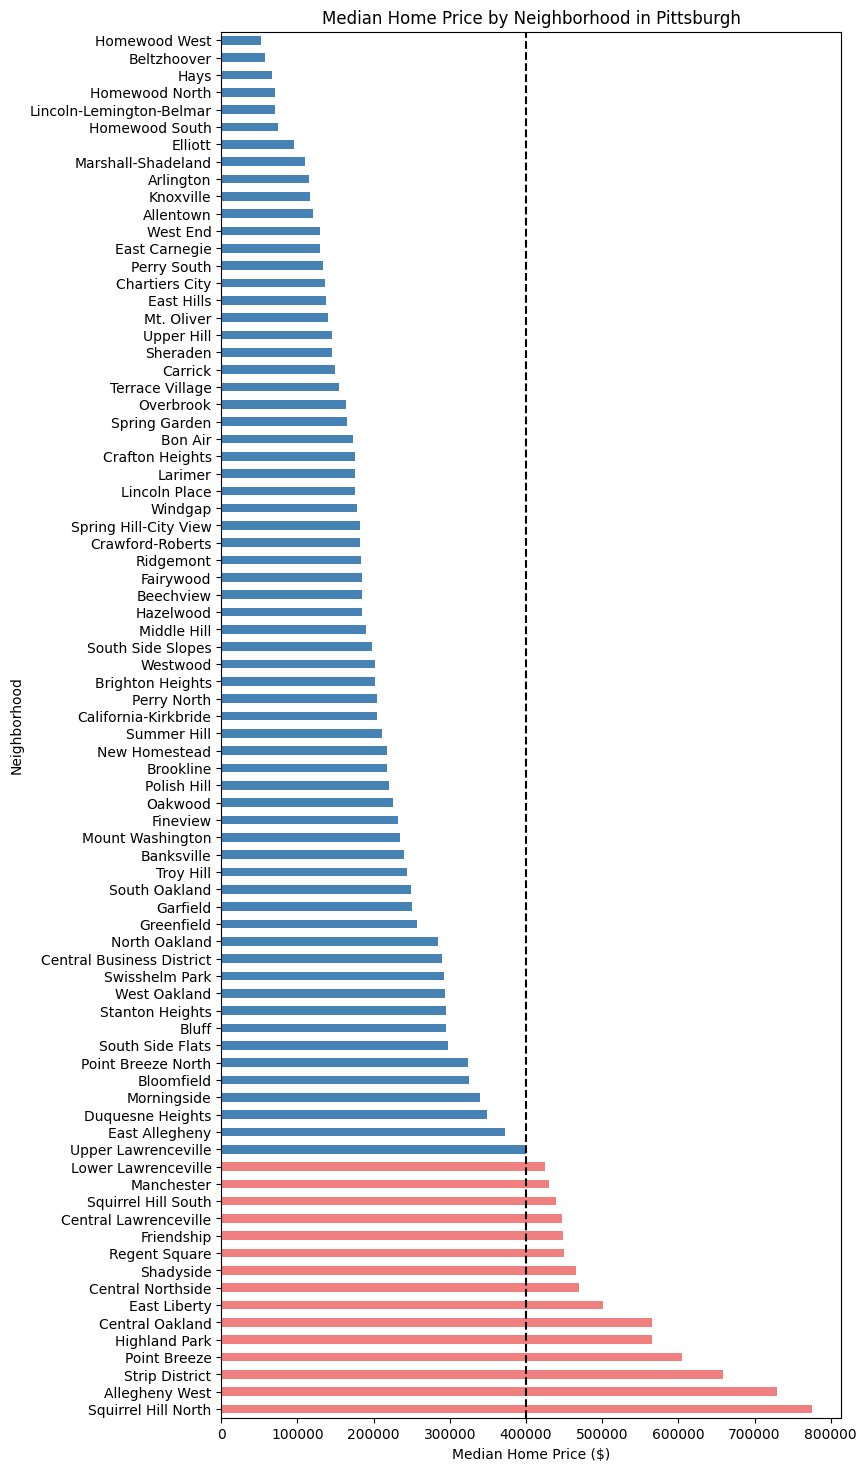

In [19]:
import matplotlib.pyplot as plt

colors = ["steelblue" if fits else "lightcoral" for fits in neighborhood_price["within_budget"]]

neighborhood_price["median"].plot.barh(figsize=(8, 18), color=colors)
plt.axvline(budget, color="black", linestyle="--")
plt.title("Median Home Price by Neighborhood in Pittsburgh")
plt.xlabel("Median Home Price ($)")
plt.ylabel("Neighborhood")
plt.gca().invert_yaxis()
plt.show()
